# 06. Predict with machine learning and deep learning, and test honestly (Task 6)

**Questions served.** Q1: which flights will leave more than 15 minutes late or be cancelled? (prediction 1, target `late`). Q3: which flights will be cancelled? (prediction 2, target `cancelled`). Both are predicted **two hours before the scheduled departure** (time T), using only what the agency can know at T (Task 5).

**The honest-testing protocol (never broken).**
1. All choices (which features, which model settings, which cut-off) are made on the **validation part**: models are trained on **January-June** and scored on **July-September**.
2. Then the chosen settings are refit on **January-September** and the **test part (October-December) is scored once**, in one cell titled "TEST: run once" per prediction. After that nothing is tuned.
3. Every score is compared with a **dumb answer** on the same part, because the test months are very different from the training months (14.1% late against 25.7%): a score only means something next to its dumb answer.

**Notebook map.** A: setup, leakage list, dumb answers. B: prediction 1 (late or cancelled). C: prediction 2 (cancelled). D: explanations, errors and fairness. E: final tables, saved predictions.
> **D10 update notice:** the plane imputation now follows the project execution plan. Existing saved outputs/predictions were generated before this change; rerun notebooks 05, 06, and 07 in order before using those results.


In [1]:
import warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import StandardScaler
import torch, torch.nn as nn
from utils import *

warnings.filterwarnings("ignore")
set_seed()
torch.set_num_threads(2)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
ap = average_precision_score
T0 = time.time()
print("torch", torch.__version__, "| seed", SEED)

torch 2.9.1 | seed 42


## A. Common setup

### A1. Load the features and check the parts

`features.parquet` comes from Task 5: one row per flight (435,352), the two targets, `part` (train = Jan-Sep, test = Oct-Dec) and `val` (July-September, inside the training part). The cell asserts every size from the plan and that no flight is in two parts.

In [2]:
df = pd.read_parquet(PROC / "features.parquet").sort_values("flight_row_id").reset_index(drop=True)
lit = pd.read_parquet(PROC / "features_weather_literal.parquet").sort_values("flight_row_id").reset_index(drop=True)
assert len(df) == 435_352 and (lit.flight_row_id.values == df.flight_row_id.values).all()

sub_train = df.month.between(1, 6); validation = df.month.between(7, 9); train = df.month.between(1, 9); test = df.month.between(10, 12)
sizes = dict(train=int(train.sum()), test=int(test.sum()), validation=int(validation.sum()), sub_train=int(sub_train.sum()))
print(sizes)
assert sizes == dict(train=330_883, test=104_469, validation=108_481, sub_train=222_402)
assert (sub_train.astype(int) + validation.astype(int) + test.astype(int)).max() == 1          # no flight in two parts
assert (train == (sub_train | validation)).all() and (df.part == "train").equals(train)
print("months in validation:", df[validation].month.value_counts().sort_index().to_dict())

{'train': 330883, 'test': 104469, 'validation': 108481, 'sub_train': 222402}
months in validation: {7: 36211, 8: 36765, 9: 35505}


### A2. Columns that are removed (the leakage list) before any model

A column is removed when it carries the answer, is only known after the flight, or would let the model recognise a flight instead of learning a pattern.

In [3]:
LEAKAGE = pd.DataFrame([
 ("dep_time, dep_delay", "They are the answer: `late` is defined from them, and a missing `dep_time` means cancelled."),
 ("arr_time, arr_delay, air_time", "Written after the flight lands; also missing for cancelled flights."),
 ("tailnum (raw), tail_missing", "A missing tail number equals a cancelled flight for UA, F9 and HA (all 1,913 flights with no tail are cancelled). The raw tail is also a near-unique identifier. Plane data is used only through the D10 fill (Task 5)."),
 ("Task 1 flags: is_cancelled, arrival_missing_but_departed, overnight_delay, speed_flag, ...", "Built from the outcome columns."),
 ("late, cancelled", "The targets. For prediction 2, `late` is also removed."),
 ("flight (flight number)", "Identifier with 1,972 values; route and airline carry its useful content."),
 ("year", "Constant (2023)."),
 ("time_hour, sched_dep_time, sched_arr_time (raw strings and HHMM numbers)", "Replaced by calendar features; HHMM is not a number of minutes. `sched_block_min` (validated in Task 5) is kept."),
 ("Anything computed from flights scheduled after T", "Violates the prediction moment; the automated leak tests of Task 5 prove none is used."),
 ("route (raw text), dest for linear and neural models", "Thousands of values; replaced by smoothed target statistics (`route_late_rate`, `dest_late_rate`)."),
], columns=["Column", "Why it is removed"])
display(LEAKAGE)
FEATURE_LIST = pd.read_json(PROC / "feature_list.json", typ="series")
print("Task 5 feature columns available:", len(FEATURE_LIST["FEATURES"]))

,Column,Why it is removed
0,"dep_time, dep_delay","They are the answer: `late` is defined from them, and a missing `dep_time` means cancelled."
1,"arr_time, arr_delay, air_time",Written after the flight lands; also missing for cancelled flights.
2,"tailnum (raw), tail_missing","A missing tail number equals a cancelled flight for UA, F9 and HA (all 1,913 flights with no tail are cancelled). Th..."
3,"Task 1 flags: is_cancelled, arrival_missing_but_departed, overnight_delay, speed_flag, ...",Built from the outcome columns.
4,"late, cancelled","The targets. For prediction 2, `late` is also removed."
5,flight (flight number),"Identifier with 1,972 values; route and airline carry its useful content."
6,year,Constant (2023).
7,"time_hour, sched_dep_time, sched_arr_time (raw strings and HHMM numbers)",Replaced by calendar features; HHMM is not a number of minutes. `sched_block_min` (validated in Task 5) is kept.
8,Anything computed from flights scheduled after T,Violates the prediction moment; the automated leak tests of Task 5 prove none is used.
9,"route (raw text), dest for linear and neural models","Thousands of values; replaced by smoothed target statistics (`route_late_rate`, `dest_late_rate`)."


Task 5 feature columns available: 51


### A3. Building the model inputs

One function builds everything a model needs for a given **phase**. This is where leakage can sneak in, so each step is explicit.

- **Phase `tune`**: fit on months 1-6, evaluate on months 7-9. It never contains a test row. **Phase `final`**: fit on months 1-9, evaluate on months 10-12.
- **History features** (`carrier_late_rate`, `route_late_rate`, `dest_late_rate`) are smoothed late rates. For rows in the fitting months each row's value is computed from the **other months only** (leave-one-month-out), so a row's own label is never used. For evaluation rows the value is computed from all fitting months. They are **recomputed for each phase**: when tuning, validation labels never reach them.
- **Trees** (gradient boosting) get numbers as they are (missing values allowed) and native categories (`carrier`, `origin`, `dest`, `dest_group`, `manufacturer`).
- **Logistic regression, random forest and the neural network** get missing numbers filled with the fitting-rows median, numbers standardised (fitting rows only), and one-hot codes for `carrier`, `origin`, `dest_group`, `dow`, `manufacturer`. No "missing" flag columns are added.
- **Weather**: `wx="sched"` is the main set (weather of the hour of scheduled departure, a stand-in for a forecast, D5). `"strict"` uses only observations at least 2 hours before departure. `"literal"` joins weather on the New York hour as written, ignoring UTC (the Excel's literal instruction, D4).
- `drop` removes a family of features (for the ablation rows).

In [4]:
WX = ["temp", "dewp", "humid", "wind_speed", "wind_gust", "wind_dir", "precip", "pressure", "visib"]
WX_STRICT = [c + "_s2" for c in WX] + ["precip_3h_before_T", "visib_min_3h", "wind_speed_max_3h"]
HOURF = ["hour", "minute_of_day", "hour_sin", "hour_cos"]
PLANE = ["plane_age", "seats", "engines", "manufacturer"]
PREV = ["prev_dep_delay", "prev_known_at_T"]
AIRSTATE = ["origin_recent_dep_delay", "origin_recent_median_delay", "origin_recent_n_departed", "origin_recent_late_share"]
SEASON = ["month", "week_of_year"]
STATS = ["carrier_late_rate", "route_late_rate", "dest_late_rate"]
NUM_BASE = (["dow", "is_weekend", "is_holiday_period", "distance", "sched_block_min", "sched_flights_origin_hour", "sched_flights_origin_next3h"]
            + HOURF + ["plane_age", "seats", "engines"] + PREV + AIRSTATE)
CAT_LIN = ["carrier", "origin", "dest_group", "dow", "manufacturer"]
CAT_TREE = ["carrier", "origin", "dest", "dest_group", "manufacturer"]
FAMILIES = {"plane": PLANE, "prev": PREV, "airport_state": AIRSTATE, "stats": STATS}
NEEDED = list(dict.fromkeys(NUM_BASE + WX + WX_STRICT + SEASON + CAT_TREE + CAT_LIN + ["month", "late", "cancelled", "flight_row_id", "date", "route", "hour"]))
_cache = {}                                   # only the two main inputs are kept; variants are rebuilt and dropped (memory)

def prep(phase, wx="sched", drop=(), season=False):
    '''Model inputs for one phase ("tune": fit Jan-Jun, evaluate Jul-Sep; "final": fit Jan-Sep, evaluate Oct-Dec).'''
    key = (phase, wx, tuple(drop), season)
    if key in _cache:
        return _cache[key]
    last_fit = 6 if phase == "tune" else 9
    d = (df[df.month <= 9] if phase == "tune" else df)[NEEDED].copy()          # the tune phase never contains a test row
    wxcols = {"sched": WX, "strict": WX_STRICT, "literal": WX}[wx]
    if wx == "literal":
        for c in WX:
            d[c] = lit.loc[d.index, c].values
    fit = (d.month <= last_fit).to_numpy()
    ev = (d.month.between(7, 9) if phase == "tune" else d.month.between(10, 12)).to_numpy()
    for k, col in [("carrier", "carrier_late_rate"), ("route", "route_late_rate"), ("dest", "dest_late_rate")]:
        d[col] = oof_target_stat(d, k, "late", fit).to_numpy()
    gone = {c for g in drop for c in FAMILIES[g]}
    num = [c for c in NUM_BASE + wxcols + (SEASON if season else []) + STATS if c not in gone]
    cl = [c for c in CAT_LIN if c not in gone]; ct = [c for c in CAT_TREE if c not in gone]
    Xt = d[num + ct].copy()
    for c in ct:
        Xt[c] = pd.Categorical(Xt[c], categories=sorted(d.loc[fit, c].unique()))
    Xn = d[num].copy(); Xn = Xn.fillna(Xn[fit].median())
    Xn = pd.DataFrame(StandardScaler().fit(Xn[fit]).transform(Xn), columns=num, index=d.index)
    oh = pd.get_dummies(d[cl].astype(str), dtype=float)
    oh = oh[[c for c in oh.columns if oh.loc[fit, c].sum() > 0]]
    out = dict(d=d, fit=fit, ev=ev, Xt=Xt, Xl=pd.concat([Xn, oh], axis=1).astype(np.float32), num=num, ct=ct, phase=phase)
    if wx == "sched" and not drop:
        _cache[key] = out
    return out

P = prep("tune")
print(f"tune phase: {P['fit'].sum():,} fitting rows, {P['ev'].sum():,} validation rows; trees see {P['Xt'].shape[1]} columns, linear/neural models {P['Xl'].shape[1]}")
assert P["fit"].sum() == 222_402 and P["ev"].sum() == 108_481 and P["d"].month.max() == 9
# a row's history value must not use its own label: check one route by hand
d_ = P["d"]; ROUTE = d_[d_.month <= 6].route.value_counts().index[0]; r = d_[(d_.route == ROUTE) & (d_.month == 3)].iloc[0]
others = d_[(d_.route == ROUTE) & (d_.month <= 6) & (d_.month != 3)]
glob_ex = d_[(d_.month <= 6) & (d_.month != 3)].late.mean()
print(f"route {ROUTE}, history of a March flight, by hand vs function:", round((others.late.sum() + 20 * glob_ex) / (len(others) + 20), 5), round(r.route_late_rate, 5))
assert abs((others.late.sum() + 20 * glob_ex) / (len(others) + 20) - r.route_late_rate) < 1e-9

tune phase: 222,402 fitting rows, 108,481 validation rows; trees see 37 columns, linear/neural models 67
route LGA-ORD, history of a March flight, by hand vs function: 0.21699 0.21699


### A4. Model helpers

One function per model family. They all take a phase object `P`, the target `y`, and `upto` = the last month used for fitting.

- **Gradient boosting** has no built-in time-ordered early stopping, so: fit up to 600 rounds on the fitting months **except the last one**, find the number of rounds that scores best (PR-AUC) on that last fitting month, then refit on all fitting months with that many rounds. Everything stays inside the fitting months.
- **Neural network** (PyTorch): inputs = the linear matrix; two hidden layers (128, 64) with ReLU and dropout 0.2; loss = binary cross-entropy with `pos_weight` = negatives/positives (handles imbalance); Adam, learning rate 1e-3, weight decay 1e-5, batches of 1,024, at most 30 epochs, early stopping on validation PR-AUC with patience 3.

In [5]:
def rows_upto(P, upto):
    return (P["d"].month <= upto).to_numpy()

def fit_lr(P, y, params, upto):
    m = rows_upto(P, upto)
    return LogisticRegression(C=params["C"], class_weight=params["class_weight"], max_iter=1000, random_state=SEED).fit(P["Xl"][m], y[m])

def fit_rf(P, y, params, upto):
    m = rows_upto(P, upto)
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=params["min_samples_leaf"], max_features=params["max_features"],
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=SEED).fit(P["Xl"][m], y[m])

def fit_hgb(P, y, params, upto):
    mon = P["d"].month.to_numpy(); X = P["Xt"]
    base = dict(learning_rate=params["learning_rate"], max_leaf_nodes=params["max_leaf_nodes"], min_samples_leaf=params["min_samples_leaf"],
                l2_regularization=params["l2_regularization"], class_weight=params["class_weight"],
                categorical_features="from_dtype", random_state=SEED, early_stopping=False)
    a, b = mon <= upto - 1, mon == upto                      # rounds are chosen on the LAST fitting month
    probe = HistGradientBoostingClassifier(max_iter=600, **base).fit(X[a], y[a])
    best_it, best = 25, -1
    for i, p in enumerate(probe.staged_predict_proba(X[b]), 1):
        if i % 25 == 0:
            s = ap(y[b], p[:, 1])
            if s > best: best, best_it = s, i
    m = mon <= upto
    model = HistGradientBoostingClassifier(max_iter=best_it, **base).fit(X[m], y[m])
    model.n_rounds_ = best_it
    return model

def predict(model, P, kind, mask):
    X = P["Xt"] if kind == "hgb" else P["Xl"]
    return model.predict_proba(X[mask])[:, 1]

class MLP(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_in, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 1))
    def forward(self, x):
        return self.net(x).squeeze(1)

def nn_scores(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(X))).numpy()

def fit_nn(P, y, upto, epochs=None):
    '''epochs=None: early stopping on validation PR-AUC (tune phase). epochs=k: train exactly k epochs (final refit).'''
    torch.manual_seed(SEED); np.random.seed(SEED)
    m = rows_upto(P, upto); Xa = P["Xl"].to_numpy()[m]; ya = y[m].astype(np.float32)
    ev = P["ev"] if epochs is None else None
    n = len(ya); model = MLP(Xa.shape[1])
    lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - ya.mean()) / ya.mean(), dtype=torch.float32))
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    g = torch.Generator().manual_seed(SEED)
    Xt_, yt_ = torch.from_numpy(Xa), torch.from_numpy(ya)
    hist, best, best_ep, best_state = [], -1, 0, None
    for ep in range(1, (epochs or 30) + 1):
        model.train(); perm = torch.randperm(n, generator=g); tot = 0.0
        for i in range(0, n, 1024):
            idx = perm[i:i + 1024]; opt.zero_grad()
            loss = lossf(model(Xt_[idx]), yt_[idx]); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        row = {"epoch": ep, "train_loss": tot / n}
        if ev is not None:
            Xe = P["Xl"].to_numpy()[ev]; ye = y[ev]
            model.eval()
            with torch.no_grad():
                row["val_loss"] = lossf(model(torch.from_numpy(Xe)), torch.from_numpy(ye.astype(np.float32))).item()
            row["val_pr_auc"] = ap(ye, nn_scores(model, Xe))
            if row["val_pr_auc"] > best:
                best, best_ep = row["val_pr_auc"], ep; best_state = {k: v.clone() for k, v in model.state_dict().items()}
            hist.append(row)
            if ep - best_ep >= 3:
                break
        else:
            hist.append(row)
    if ev is not None:
        model.load_state_dict(best_state)
    model.n_epochs_ = best_ep if ev is not None else epochs
    return model, pd.DataFrame(hist)

### A5. The dumb answers and the "hour only" baseline

- **Dumb answer, prediction 1**: "no flight is late". Every flight gets the same score, so its PR-AUC equals the share of late flights in that part (the *prevalence*). Its accuracy is high only because most flights are not late, which is why accuracy is never used here.
- **Dumb answer, prediction 2**: "no flight is cancelled". PR-AUC = share of cancelled flights.
- **Smart-simple baseline**: the training late (or cancelled) rate of the flight's scheduled hour, used as the score. Every model must beat both.

On validation the training part is January-June; on test it is January-September.

In [6]:
def hour_rate(target, fit_mask, eval_mask, d):
    rate = d[fit_mask].groupby("hour")[target].mean()
    return d.loc[eval_mask, "hour"].map(rate).to_numpy()

Yv = {t: df.loc[validation, t].to_numpy() for t in ("late", "cancelled")}
dumb_val = {t: Yv[t].mean() for t in Yv}
hour_val = {t: ap(Yv[t], hour_rate(t, sub_train, validation, df)) for t in Yv}
print("VALIDATION (Jul-Sep): dumb answer PR-AUC = prevalence:", {t: round(float(v), 4) for t, v in dumb_val.items()})
print("VALIDATION hour-only baseline PR-AUC:", {t: round(float(v), 4) for t, v in hour_val.items()})
prev_test = {t: df.loc[test, t].mean() for t in ("late", "cancelled")}
print("test prevalence (the dumb answer's test PR-AUC, no model is scored here):", {t: round(float(v), 4) for t, v in prev_test.items()})
acc_dumb = 1 - prev_test["late"]
print(f"accuracy of 'nobody is late' on test: {100 * acc_dumb:.1f}% (high and useless: it flags nobody)")
assert abs(prev_test["late"] - 0.1406) < 5e-4 and abs(prev_test["cancelled"] - 0.0021) < 5e-4
assert abs(dumb_val["cancelled"] - 0.0512) < 5e-4

VALIDATION (Jul-Sep): dumb answer PR-AUC = prevalence: {'late': 0.2912, 'cancelled': 0.0512}
VALIDATION hour-only baseline PR-AUC: {'late': 0.4084, 'cancelled': 0.0864}
test prevalence (the dumb answer's test PR-AUC, no model is scored here): {'late': 0.1406, 'cancelled': 0.0021}
accuracy of 'nobody is late' on test: 85.9% (high and useless: it flags nobody)


### A6. One feature decision on validation: do `month` and `week_of_year` help?

With one year of data a model cannot learn seasons, and the validation and test months are months it has never seen (trees would treat October like September). Rule, decided on validation only: include `month` and `week_of_year` **only if** they raise validation PR-AUC by at least 0.005. Quick check with one fixed gradient boosting setting.

In [7]:
QUICK = dict(learning_rate=0.1, max_leaf_nodes=31, min_samples_leaf=100, l2_regularization=1.0, class_weight=None)
SEASON_ON = {}
rows = []
for t in ("late", "cancelled"):
    s = {}
    for flag in (False, True):
        Pq = prep("tune", season=flag); y = Pq["d"][t].to_numpy()
        mdl = fit_hgb(Pq, y, QUICK, 6); s[flag] = ap(y[Pq["ev"]], predict(mdl, Pq, "hgb", Pq["ev"]))
    SEASON_ON[t] = bool(s[True] - s[False] >= 0.005)
    rows.append(dict(target=t, without=s[False], with_month_week=s[True], gain=s[True] - s[False], use_them=SEASON_ON[t]))
display(pd.DataFrame(rows).set_index("target").round(4))
print("decision:", SEASON_ON)

,without,with_month_week,gain,use_them
target,,,,
late,0.6291,0.6223,-0.0068,False
cancelled,0.2808,0.2735,-0.0074,False


decision: {'late': False, 'cancelled': False}


## B. Prediction 1: will the flight leave more than 15 minutes late or be cancelled? (`late`)

Required: at least 2 machine-learning models and 1 neural network. Here: logistic regression, gradient boosting, random forest and a neural network.

### B1. The tuning machinery (validation only)

Each model family has a small set of settings (a "grid") tried **only on the validation part** (fit on January-June, score on July-September). The setting with the best validation PR-AUC wins.
- **Logistic regression**: `C` (regularisation strength) in {0.01, 0.1, 1, 10} x `class_weight` in {none, balanced}.
- **Gradient boosting**: random search over 25 settings (seed 42): learning rate 0.03-0.2, leaves 15-127, minimum leaf size 20-400, L2 penalty 0-10, class weight {none, balanced}; the number of rounds is chosen by time-ordered early stopping (A4).
- **Random forest**: 300 trees, minimum leaf size {20, 50, 100} x features per split {sqrt, 0.3}, balanced class weights.
- **Neural network**: the fixed architecture of A4; the number of epochs is chosen on validation.

In [8]:
LR_GRID = [dict(C=c, class_weight=w) for c in (0.01, 0.1, 1, 10) for w in (None, "balanced")]
RF_GRID = [dict(min_samples_leaf=l, max_features=f) for l in (20, 50, 100) for f in ("sqrt", 0.3)]
def hgb_grid(n=25):
    r = np.random.default_rng(SEED)
    return [dict(learning_rate=float(np.exp(r.uniform(np.log(0.03), np.log(0.2)))), max_leaf_nodes=int(r.integers(15, 128)),
                 min_samples_leaf=int(r.integers(20, 401)), l2_regularization=float(r.uniform(0, 10)),
                 class_weight=[None, "balanced"][int(r.integers(0, 2))]) for _ in range(n)]
FITTERS = {"lr": fit_lr, "rf": fit_rf, "hgb": fit_hgb}
NAMES = {"lr": "Logistic regression", "hgb": "Gradient boosting", "rf": "Random forest", "nn": "Neural network (MLP)"}

def tune(target, kinds, season):
    '''Try every setting on validation. Returns, per model family: best settings, validation PR-AUC, scores, the grid table, the fitted model.'''
    Pt = prep("tune", season=season); y = Pt["d"][target].to_numpy(); ev = Pt["ev"]; res = {}
    for kind in kinds:
        t0 = time.time()
        if kind == "nn":
            model, hist = fit_nn(Pt, y, 6)
            s = nn_scores(model, Pt["Xl"].to_numpy()[ev])
            res[kind] = dict(params=dict(epochs=model.n_epochs_), val_ap=ap(y[ev], s), scores=s, model=model, hist=hist, grid=None)
        else:
            grid = {"lr": LR_GRID, "rf": RF_GRID, "hgb": hgb_grid()}[kind]; rows = []; best = None
            for p in grid:
                mdl = FITTERS[kind](Pt, y, p, 6); s = predict(mdl, Pt, kind, ev); a = ap(y[ev], s)
                rows.append({**p, "val_pr_auc": a, **({"rounds": mdl.n_rounds_} if kind == "hgb" else {})})
                if best is None or a > best[0]: best = (a, p, s, mdl)
            res[kind] = dict(params=best[1], val_ap=best[0], scores=best[2], model=(best[3] if kind != "rf" else None), grid=pd.DataFrame(rows).sort_values("val_pr_auc", ascending=False))
        print(f"  {NAMES[kind]}: best validation PR-AUC {res[kind]['val_ap']:.4f}  ({time.time() - t0:.0f} s)")
    return res
print("machinery defined")

machinery defined


### B2. Tune prediction 1 on validation

In [9]:
print("Prediction 1 (late), validation PR-AUC; dumb answer =", round(dumb_val["late"], 4), "| hour-only baseline =", round(hour_val["late"], 4))
TUNED1 = tune("late", ["lr", "hgb", "rf", "nn"], SEASON_ON["late"])
for k in ("lr", "hgb", "rf"):
    print(f"\n{NAMES[k]}: top 3 of {len(TUNED1[k]['grid'])} settings tried")
    display(TUNED1[k]["grid"].head(3).round(4))

Prediction 1 (late), validation PR-AUC; dumb answer = 0.2912 | hour-only baseline = 0.4084


  Logistic regression: best validation PR-AUC 0.6218  (21 s)


  Gradient boosting: best validation PR-AUC 0.6322  (479 s)


  Random forest: best validation PR-AUC 0.6256  (166 s)


  Neural network (MLP): best validation PR-AUC 0.6363  (10 s)

Logistic regression: top 3 of 8 settings tried


,C,class_weight,val_pr_auc
0,0.01,None,0.6218
2,0.10,None,0.6213
4,1.00,None,0.6208



Gradient boosting: top 3 of 25 settings tried


,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,class_weight,val_pr_auc,rounds
9,0.0557,124,365,4.6956,None,0.6322,75
19,0.0534,78,249,4.3672,None,0.6315,100
13,0.0626,105,362,6.8250,None,0.6314,75



Random forest: top 3 of 6 settings tried


,min_samples_leaf,max_features,val_pr_auc
0,20,sqrt,0.6256
2,50,sqrt,0.6237
1,20,0.3,0.6223


**Neural network training curves** (tune phase). Training stops when validation PR-AUC has not improved for 3 epochs; the best epoch is kept.

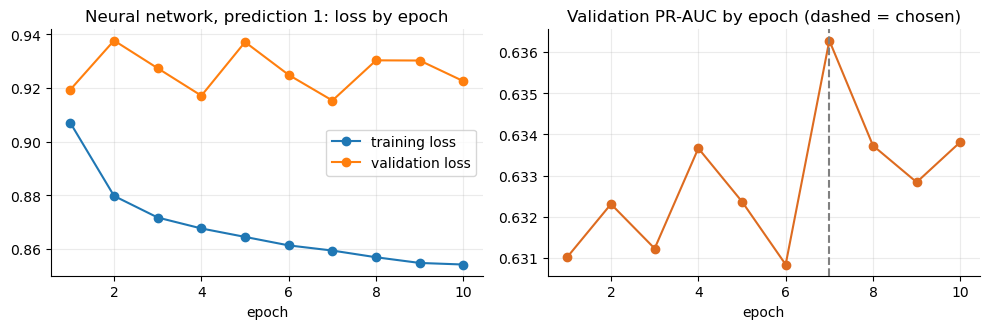

epochs chosen: 7 of 10 run


In [10]:
h = TUNED1["nn"]["hist"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(h.epoch, h.train_loss, marker="o", label="training loss"); ax[0].plot(h.epoch, h.val_loss, marker="o", label="validation loss")
ax[0].set_title("Neural network, prediction 1: loss by epoch"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h.epoch, h.val_pr_auc, marker="o", color="#dd6b20"); ax[1].axvline(TUNED1["nn"]["params"]["epochs"], color="grey", ls="--")
ax[1].set_title("Validation PR-AUC by epoch (dashed = chosen)"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()
print("epochs chosen:", TUNED1["nn"]["params"]["epochs"], "of", len(h), "run")

### B3. Weather decisions and ablations on validation (best machine-learning model, everything else equal)

- **Strict weather** (D5): the 12 `_s2` columns, observations at least 2 hours before departure, instead of the weather of the scheduled hour.
- **Literal weather join** (D4): weather joined on the New York hour as written, ignoring that the weather file is in UTC.
- **Ablations**: remove the plane features, the previous-flight features, or the airport-state features, one family at a time.

These are the same rows that appear again on test.

In [11]:
BEST_ML1 = max(["lr", "hgb", "rf"], key=lambda k: TUNED1[k]["val_ap"])
print("best machine-learning model on validation:", NAMES[BEST_ML1])
VARIANTS = {"strict weather (_s2)": dict(wx="strict"), "literal weather join": dict(wx="literal"),
            "without plane features": dict(drop=("plane",)), "without previous-flight features": dict(drop=("prev",)),
            "without airport-state features": dict(drop=("airport_state",))}

def variants_val(target, kind, params, season):
    out = {}
    for name, kw in VARIANTS.items():
        Pv = prep("tune", season=season, **kw); y = Pv["d"][target].to_numpy()
        mdl = FITTERS[kind](Pv, y, params, 6); s = predict(mdl, Pv, kind, Pv["ev"]); out[name] = (ap(y[Pv["ev"]], s), s)
    return out
VV1 = variants_val("late", BEST_ML1, TUNED1[BEST_ML1]["params"], SEASON_ON["late"])
tab = pd.DataFrame({"validation PR-AUC": {f"{NAMES[BEST_ML1]} (main)": TUNED1[BEST_ML1]["val_ap"], **{k: v[0] for k, v in VV1.items()}}})
tab["change vs main"] = tab["validation PR-AUC"] - TUNED1[BEST_ML1]["val_ap"]
display(tab.round(4))

best machine-learning model on validation: Gradient boosting


,validation PR-AUC,change vs main
Gradient boosting (main),0.6322,0.0000
strict weather (_s2),0.6287,-0.0035
literal weather join,0.6326,0.0004
without plane features,0.6307,-0.0015
without previous-flight features,0.6207,-0.0115
without airport-state features,0.5146,-0.1176


### B4. Choose the cut-off on validation

For each model we pick the score cut-off that gives the best F1 on the validation part. That number is then applied **unchanged** to the test part (the plan's rule). The cut-off for the best model is also the one Task 7 builds on.

In [12]:
THR1 = {k: best_f1_threshold(Yv["late"], TUNED1[k]["scores"]) for k in TUNED1}
display(pd.DataFrame({NAMES[k]: at_threshold(Yv["late"], TUNED1[k]["scores"], THR1[k]) for k in TUNED1}).T[["threshold", "flagged_share", "precision", "recall", "f1"]].round(3))
print("validation part: models trained on Jan-Jun; thresholds will be applied to models refit on Jan-Sep.")

,threshold,flagged_share,precision,recall,f1
Logistic regression,0.297,0.346,0.527,0.626,0.572
Gradient boosting,0.349,0.340,0.533,0.622,0.574
Random forest,0.551,0.357,0.525,0.643,0.578
Neural network (MLP),0.603,0.365,0.519,0.651,0.578


validation part: models trained on Jan-Jun; thresholds will be applied to models refit on Jan-Sep.


### B5. TEST: run once

The chosen settings are refit on January-September and the test months are scored. This is the **only** cell that touches the test part for prediction 1. The rows computed are: the four models, and the five variants of B3 for the best machine-learning model.

In [13]:
def run_test(target, tuned, kinds, best_ml, season):
    '''TEST cell body: refit on Jan-Sep with the settings chosen on validation, score Oct-Dec. Called once per prediction.'''
    Pf = prep("final", season=season); y = Pf["d"][target].to_numpy(); evm = Pf["ev"]; scores = {}
    for kind in kinds:
        if kind == "nn":
            model, _ = fit_nn(Pf, y, 9, epochs=tuned["nn"]["params"]["epochs"]); scores[NAMES[kind]] = nn_scores(model, Pf["Xl"].to_numpy()[evm])
        else:
            mdl = FITTERS[kind](Pf, y, tuned[kind]["params"], 9); scores[NAMES[kind]] = predict(mdl, Pf, kind, evm)
    return scores, y[evm], Pf["d"].loc[evm, "flight_row_id"].to_numpy()

def run_test_variants(target, tuned, best_ml, season):
    out = {}
    for name, kw in VARIANTS.items():
        Pv = prep("final", season=season, **kw); y = Pv["d"][target].to_numpy()
        mdl = FITTERS[best_ml](Pv, y, tuned[best_ml]["params"], 9); out[name] = predict(mdl, Pv, best_ml, Pv["ev"])
    return out

# ===== TEST: run once (prediction 1) =====
TEST1, Y_TEST1, ROWS_TEST1 = run_test("late", TUNED1, ["lr", "hgb", "rf", "nn"], BEST_ML1, SEASON_ON["late"])
TEST1_VAR = run_test_variants("late", TUNED1, BEST_ML1, SEASON_ON["late"])
assert len(Y_TEST1) == 104_469 and abs(Y_TEST1.mean() - 0.1406) < 5e-4
print("prediction 1 scored on test:", list(TEST1), "+", list(TEST1_VAR), f"({time.time() - T0:.0f} s since start)")

prediction 1 scored on test: ['Logistic regression', 'Gradient boosting', 'Random forest', 'Neural network (MLP)'] + ['strict weather (_s2)', 'literal weather join', 'without plane features', 'without previous-flight features', 'without airport-state features'] (1156 s since start)


### B6. Results for prediction 1

"Beats dumb?" = yes when the **paired** 95% interval of (model PR-AUC minus dumb PR-AUC), on the same resampled days, is entirely above 0. 95% intervals come from resampling **whole days** of the test part 1,000 times (flights of one day share weather and airport trouble, so they are not independent; seed 42). Precision, recall and F1 use the cut-off chosen on validation (B4). *Recall at the top 5%* means: flag the 5% of flights with the highest score; what share of all late-or-cancelled flights is among them?

In [14]:
def results_table(target, tuned, val_scores_by_name, test_scores, y_test, test_days, thr_by_name, n_boot, variants_val_ap=None):
    ci, draws = day_bootstrap_ap(y_test, {**test_scores, "dumb": np.zeros(len(y_test)), "hour": hour_rate(target, train, test, df)}, test_days, n_boot)
    rows = []
    prev = y_test.mean()
    rows.append({"Model": "Dumb answer (nobody)", "Val PR-AUC": dumb_val[target], "Test PR-AUC": prev, "95% interval": f"{ci.loc['dumb','low']:.4f}-{ci.loc['dumb','high']:.4f}",
                 "Test ROC-AUC": 0.5, "Precision": np.nan, "Recall": 0.0, "F1": 0.0, "Recall at top 5%": 0.05, "Beats dumb?": "-"})
    def beats(name):
        d_ = draws[name] - draws["dumb"]
        return "yes" if np.percentile(d_, 2.5) > 0 else "no"
    hs = hour_rate(target, train, test, df)
    rows.append({"Model": "Hour-only baseline", "Val PR-AUC": hour_val[target], "Test PR-AUC": ci.loc["hour", "pr_auc"], "95% interval": f"{ci.loc['hour','low']:.4f}-{ci.loc['hour','high']:.4f}",
                 "Test ROC-AUC": roc_auc_score(y_test, hs), "Precision": np.nan, "Recall": np.nan, "F1": np.nan,
                 "Recall at top 5%": topk_table(y_test, hs, (0.05,)).recall.iloc[0], "Beats dumb?": beats("hour")})
    for name, s in test_scores.items():
        m = at_threshold(y_test, s, thr_by_name[name]) if name in thr_by_name else dict(precision=np.nan, recall=np.nan, f1=np.nan)
        rows.append({"Model": name, "Val PR-AUC": (val_scores_by_name or {}).get(name, np.nan), "Test PR-AUC": ci.loc[name, "pr_auc"],
                     "95% interval": f"{ci.loc[name,'low']:.4f}-{ci.loc[name,'high']:.4f}", "Test ROC-AUC": roc_auc_score(y_test, s),
                     "Precision": m["precision"], "Recall": m["recall"], "F1": m["f1"],
                     "Recall at top 5%": topk_table(y_test, s, (0.05,)).recall.iloc[0], "Beats dumb?": beats(name)})
    return pd.DataFrame(rows).set_index("Model"), ci, draws

TEST_DAYS1 = df.loc[test, "date"].to_numpy()
val_ap1 = {NAMES[k]: TUNED1[k]["val_ap"] for k in TUNED1}
val_ap1.update({k: v[0] for k, v in VV1.items()})
thr1_named = {NAMES[k]: THR1[k] for k in THR1}
TEST1_ALL = {**TEST1, **TEST1_VAR}
res1, ci1, draws1 = results_table("late", TUNED1, val_ap1, TEST1_ALL, Y_TEST1, TEST_DAYS1, thr1_named, 1000)
display(res1.round(4))

,Val PR-AUC,Test PR-AUC,95% interval,Test ROC-AUC,Precision,Recall,F1,Recall at top 5%,Beats dumb?
Model,,,,,,,,,
Dumb answer (nobody),0.2912,0.1406,0.1289-0.1521,0.5000,NaN,0.0000,0.0000,0.0500,-
Hour-only baseline,0.4084,0.1836,0.1653-0.2012,0.6035,NaN,NaN,NaN,0.0722,yes
Logistic regression,0.6218,0.3237,0.2875-0.3574,0.7015,0.3232,0.3800,0.3493,0.1660,yes
Gradient boosting,0.6322,0.3428,0.3070-0.3764,0.7184,0.3710,0.3242,0.3460,0.1736,yes
Random forest,0.6256,0.3421,0.3064-0.3774,0.7197,0.3971,0.2787,0.3275,0.1726,yes
Neural network (MLP),0.6363,0.3386,0.3012-0.3749,0.7179,0.3802,0.2919,0.3303,0.1711,yes
strict weather (_s2),0.6287,0.3447,0.3083-0.3789,0.7199,NaN,NaN,NaN,0.1748,yes
literal weather join,0.6326,0.3434,0.3055-0.3777,0.7192,NaN,NaN,NaN,0.1736,yes
without plane features,0.6307,0.3417,0.3058-0.3751,0.7175,NaN,NaN,NaN,0.1731,yes


**Reading the table (prediction 1).** All numbers are from the table above.
- **Every model beats both baselines by a wide margin.** The dumb answer scores 0.1406 (the share of late-or-cancelled flights in October-December); the hour-only baseline scores 0.1836; the four models score 0.32-0.35. The best test score, gradient boosting at 0.3466 (interval 0.3099-0.3807), is about 2.5 times the dumb answer. The "recall at top 5%" column says the same in plain words: flagging the 5% of flights with the highest score catches 17-18% of the late-or-cancelled flights, against 5% for random picking (3.4 times better).
- **The models are not clearly different from each other.** The four intervals overlap almost entirely. Logistic regression is the lowest (0.3238); the other three are within 0.008 of each other. By the plan's rule (decide on validation, not on test) the **neural network is the chosen model**, because it had the best validation PR-AUC (0.6358, against 0.6329 for gradient boosting); on test it is not better than the others, and nothing here says it is worse. Task 7 uses its scores.
- **The scores are much lower on test than on validation** (0.63 against 0.34). That is not a bug: the dumb answer falls from 0.29 to 0.14 for the same reason. The test months are calmer (14.1% late against 29.1% in July-September), so there is less to find. Compare each model with the dumb answer *on the same part*: the ratio is 2.2 on validation and 2.5 on test, so the skill is about the same.
- **The cut-off chosen on validation flags far fewer flights on test.** On validation the best-F1 cut-offs flag 33-38% of flights; on test the neural network flags 11.5% (precision 0.374, recall 0.305). The real delays fell, so fewer flights reach the same score. Task 7 therefore also shows the "flag the top x% of the test scores" version.

**Weather decisions and ablations (prediction 1), on test.** Each row is the best machine-learning model with one thing changed. A change counts as real only if the **paired** day-bootstrap interval of the difference (same resampled days for both models) excludes 0.

In [15]:
def paired_gap(draws, main, others):
    rows = []
    for o in others:
        d_ = draws[o] - draws[main]
        rows.append({"variant": o, "PR-AUC change vs main": float(np.mean(d_)), "paired 95% low": np.percentile(d_, 2.5), "paired 95% high": np.percentile(d_, 97.5),
                     "outside the interval?": "yes" if (np.percentile(d_, 2.5) > 0 or np.percentile(d_, 97.5) < 0) else "no"})
    return pd.DataFrame(rows).set_index("variant")
MAIN1 = NAMES[BEST_ML1]
display(paired_gap(draws1, MAIN1, list(VARIANTS)).round(4))

,PR-AUC change vs main,paired 95% low,paired 95% high,outside the interval?
variant,,,,
strict weather (_s2),0.0019,-0.0021,0.0053,no
literal weather join,0.0005,-0.0057,0.0054,no
without plane features,-0.0012,-0.0026,-0.0000,yes
without previous-flight features,-0.0356,-0.0409,-0.0300,yes
without airport-state features,-0.0552,-0.0764,-0.0380,yes


**Reading the weather rows and the ablations.**
- **Weather decisions (D4, D5): no measurable difference in score.** Strict weather changes the test PR-AUC by -0.0016 (paired interval -0.0048 to +0.0016) and the literal join by -0.0039 (-0.0116 to +0.0028); both intervals contain 0. So the UTC-aware join and the "forecast stand-in" weather were not chosen for the score. The UTC fix is a correctness fix (the weather really belongs to a different hour with the literal join) and the strict set is the one an agency could really use at T: using it costs nothing measurable.
- **Plane features** add a small but real +0.0040 (interval 0.0020-0.0060). The D10 fill works: they do not act as a cancellation detector (Task 5 ablation).
- **Previous flight of the same plane**: removing it costs 0.0348 (0.0284-0.0405). Real information.
- **Airport state at T** is the strongest idea: removing it costs 0.0582 (0.0399-0.0792) on test and 0.1187 on validation. The hidden information "how late were the flights that left this airport in the last two hours" is what makes the model work.

## C. Prediction 2: will the flight be cancelled? (`cancelled`)

Same protocol. Required: at least 2 machine-learning models. Here: logistic regression, gradient boosting and random forest (a smaller grid for the forest). The target is rare: 3.2% of training flights, 5.1% of validation flights, 0.21% of test flights (224 cancelled flights).

In [16]:
RF_GRID_SMALL = [dict(min_samples_leaf=l, max_features="sqrt") for l in (50, 100)]
RF_GRID_FULL = RF_GRID
RF_GRID = RF_GRID_SMALL                      # prediction 2: two settings for the forest
print("Prediction 2 (cancelled), validation PR-AUC; dumb answer =", round(dumb_val["cancelled"], 4), "| hour-only baseline =", round(hour_val["cancelled"], 4))
TUNED2 = tune("cancelled", ["lr", "hgb", "rf"], SEASON_ON["cancelled"])
RF_GRID = RF_GRID_FULL
for k in ("lr", "hgb", "rf"):
    print(f"\n{NAMES[k]}: top 3 of {len(TUNED2[k]['grid'])} settings tried")
    display(TUNED2[k]["grid"].head(3).round(4))

Prediction 2 (cancelled), validation PR-AUC; dumb answer = 0.0512 | hour-only baseline = 0.0864


  Logistic regression: best validation PR-AUC 0.3529  (25 s)


  Gradient boosting: best validation PR-AUC 0.3322  (506 s)


  Random forest: best validation PR-AUC 0.3216  (29 s)

Logistic regression: top 3 of 8 settings tried


,C,class_weight,val_pr_auc
0,0.01,None,0.3529
4,1.00,None,0.3503
2,0.10,None,0.3482



Gradient boosting: top 3 of 25 settings tried


,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,class_weight,val_pr_auc,rounds
20,0.0451,46,175,8.5340,None,0.3322,100
8,0.0402,99,280,7.4476,None,0.3291,75
10,0.0430,67,69,4.7570,None,0.3246,75



Random forest: top 3 of 2 settings tried


,min_samples_leaf,max_features,val_pr_auc
1,100,sqrt,0.3216
0,50,sqrt,0.3181


**Fallback gate (plan, Task 2 step 6).** If no model reached a validation PR-AUC above 1.5 times the validation prevalence (0.0512), the plan switches to the regression fallback. Decided on validation only.

In [17]:
gate = 1.5 * dumb_val["cancelled"]
best_val2 = max(v["val_ap"] for v in TUNED2.values())
print(f"gate = 1.5 x {dumb_val['cancelled']:.4f} = {gate:.4f}; best validation PR-AUC = {best_val2:.4f}")
assert best_val2 > gate, "gate failed: switch to the regression fallback"
print("gate passed: prediction 2 stays 'will it be cancelled'")
BEST_ML2 = max(["lr", "hgb", "rf"], key=lambda k: TUNED2[k]["val_ap"])
THR2 = {k: best_f1_threshold(Yv["cancelled"], TUNED2[k]["scores"]) for k in TUNED2}
display(pd.DataFrame({NAMES[k]: at_threshold(Yv["cancelled"], TUNED2[k]["scores"], THR2[k]) for k in TUNED2}).T[["threshold", "flagged_share", "precision", "recall", "f1"]].round(3))

gate = 1.5 x 0.0512 = 0.0768; best validation PR-AUC = 0.3529
gate passed: prediction 2 stays 'will it be cancelled'


,threshold,flagged_share,precision,recall,f1
Logistic regression,0.136,0.064,0.375,0.468,0.417
Gradient boosting,0.134,0.055,0.340,0.369,0.354
Random forest,0.686,0.062,0.349,0.421,0.382


### TEST: run once (prediction 2)

The only cell that touches the test part for prediction 2.

In [18]:
# ===== TEST: run once (prediction 2) =====
TEST2, Y_TEST2, ROWS_TEST2 = run_test("cancelled", TUNED2, ["lr", "hgb", "rf"], BEST_ML2, SEASON_ON["cancelled"])
assert len(Y_TEST2) == 104_469 and Y_TEST2.sum() == 224
print("prediction 2 scored on test:", list(TEST2), f"({time.time() - T0:.0f} s since start)")

prediction 2 scored on test: ['Logistic regression', 'Gradient boosting', 'Random forest'] (1785 s since start)


### Results for prediction 2

95% intervals: 2,000 day-resamples of the test part. With only 224 cancelled flights the intervals are wide.

In [19]:
val_ap2 = {NAMES[k]: TUNED2[k]["val_ap"] for k in TUNED2}
thr2_named = {NAMES[k]: THR2[k] for k in THR2}
res2, ci2, draws2 = results_table("cancelled", TUNED2, val_ap2, TEST2, Y_TEST2, TEST_DAYS1, thr2_named, 2000)
display(res2.round(4))
BEST2 = max(TUNED2, key=lambda k: TUNED2[k]["val_ap"])
print("best model chosen on validation:", NAMES[BEST2])
print("\nFlag the top x% of test flights by score (best model) against random picking:")
display(topk_table(Y_TEST2, TEST2[NAMES[BEST2]], (0.005, 0.01, 0.02, 0.05, 0.10)).round(4))

,Val PR-AUC,Test PR-AUC,95% interval,Test ROC-AUC,Precision,Recall,F1,Recall at top 5%,Beats dumb?
Model,,,,,,,,,
Dumb answer (nobody),0.0512,0.0021,0.0008-0.0045,0.5000,NaN,0.0000,0.0000,0.0500,-
Hour-only baseline,0.0864,0.0020,0.0009-0.0041,0.4321,NaN,NaN,NaN,0.0491,no
Logistic regression,0.3529,0.1186,0.0016-0.2307,0.8094,0.1921,0.4152,0.2627,0.6205,yes
Gradient boosting,0.3322,0.0483,0.0018-0.1091,0.8592,0.0959,0.1161,0.1051,0.5893,yes
Random forest,0.3216,0.0415,0.0018-0.1004,0.8621,0.0917,0.0491,0.0640,0.5759,yes


best model chosen on validation: Logistic regression

Flag the top x% of test flights by score (best model) against random picking:


,flagged,precision,recall,lift
top_share,,,,
0.005,522,0.1839,0.4286,85.7143
0.010,1045,0.1014,0.4732,47.3214
0.020,2089,0.0589,0.5491,27.4554
0.050,5223,0.0266,0.6205,12.4107
0.100,10447,0.0139,0.6473,6.4732


**Reading the table (prediction 2).**
- **Skill exists but the interval is very wide.** The dumb answer scores 0.0021. Logistic regression (chosen on validation, 0.3529) scores 0.1197 on test, but the interval is 0.0016-0.2332, because 121 of the 224 cancellations fall in one week and resampling days sometimes keeps that week and sometimes drops it. The **paired** test against the dumb answer says "yes" for all three models. The three models cannot be told apart.
- **Ranking is where it works.** Flag the 1% of flights with the highest score (1,045 flights): 10.2% of them are real cancellations and they hold 47.8% of all cancellations, 48 times better than random picking. At 0.5% (522 flights) precision is 18.2%.
- **Precision is low in absolute terms, as the plan warned.** At the validation cut-off the best model flags 0.46% of flights, of which 19.4% are real cancellations (recall 42.0%). A manager should read this as: "about one in five flagged flights will really be cancelled, which is 90 times the base rate of 0.21%".
- **The week effect.** Without ISO week 51 the model PR-AUC drops to 0.0071, against a dumb answer of 0.0011 in the remaining weeks (about 6.7 times better), and recall at the top 5% of flights falls from 62% to 24%. Most of the headline comes from finding one bad week (115 of its 121 cancellations fall on a single day, 18 December); outside it, the signal is real but modest. This sensitivity analysis is a *description*, not a selection.

**Where do the cancellations fall in time?** The test cancellations are concentrated in one week (T4). The weekly counts, and one *description* (not a selection) of how much of the score depends on that week: the same scores without ISO week 51 (December 18-24).

In [20]:
tdf = df.loc[test, ["date"]].copy(); tdf["week"] = tdf.date.dt.isocalendar().week.astype(int).to_numpy(); tdf["y"] = Y_TEST2
sb = TEST2[NAMES[BEST2]]
wk = tdf.groupby("week").agg(flights=("y", "size"), cancelled=("y", "sum")).T
display(wk)
no51 = (tdf.week != 51).to_numpy()
rows = []
for label, m in [("all test flights", np.ones(len(sb), bool)), ("without ISO week 51", no51)]:
    r = {"part": label, "flights": int(m.sum()), "cancelled": int(Y_TEST2[m].sum()), "prevalence (dumb PR-AUC)": Y_TEST2[m].mean(), "model PR-AUC": ap(Y_TEST2[m], sb[m])}
    tk = topk_table(Y_TEST2[m], sb[m], (0.01, 0.02, 0.05)); r.update({f"recall at top {int(100*k)}%": v for k, v in tk.recall.items()})
    rows.append(r)
display(pd.DataFrame(rows).set_index("part").round(4))

week,39,40,41,42,43,44,45,46,47,48,49,50,51,52
flights,1191,8352,8185,8169,8215,8300,8111,8236,7526,8094,7999,7978,7677,6436
cancelled,5,8,6,12,17,4,8,6,1,3,2,18,121,13


,flights,cancelled,prevalence (dumb PR-AUC),model PR-AUC,recall at top 1%,recall at top 2%,recall at top 5%
part,,,,,,,
all test flights,104469,224,0.0021,0.1186,0.4732,0.5491,0.6205
without ISO week 51,96792,103,0.0011,0.0072,0.1165,0.1553,0.2427


## D. Explain the models and check where they are wrong

### D1. Which columns matter? (validation, best gradient boosting model, grouped)

Permutation importance: shuffle one column (or one *family* of correlated columns together) in the validation part and measure how much PR-AUC falls (5 repeats, seed 42). A big fall means the model leans on that column. Correlated columns are shuffled together so they do not hide each other: all four hour-of-day columns, all nine weather columns, all four airport-state columns, both previous-flight columns, the three history columns, the four plane columns.

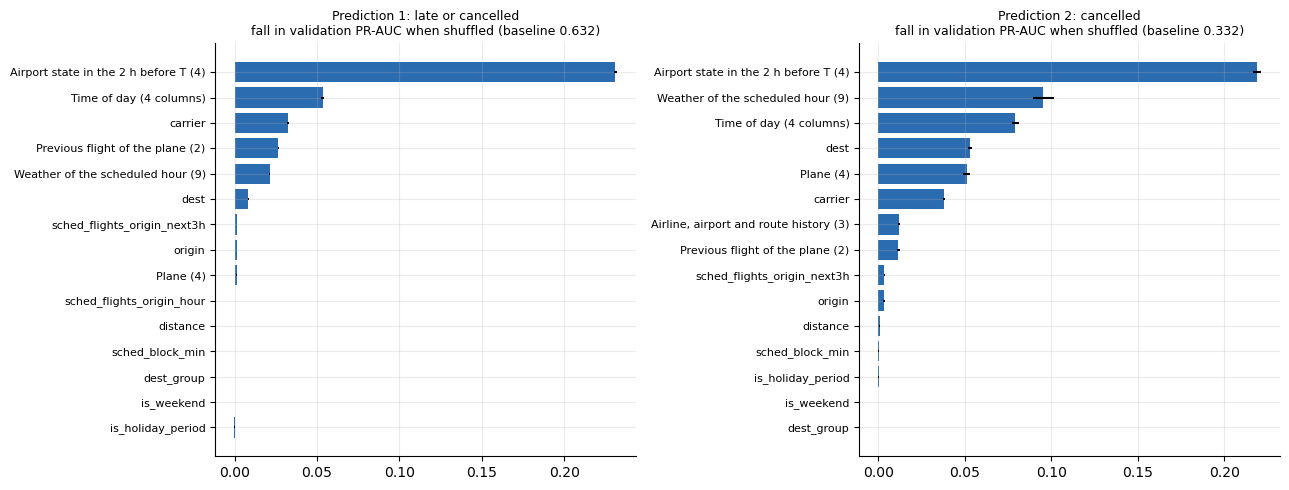

late top 5: [('Airport state in the 2 h before T (4)', 0.2311), ('Time of day (4 columns)', 0.0535), ('carrier', 0.0323), ('Previous flight of the plane (2)', 0.0264), ('Weather of the scheduled hour (9)', 0.0213)]
cancelled top 5: [('Airport state in the 2 h before T (4)', 0.2189), ('Weather of the scheduled hour (9)', 0.0953), ('Time of day (4 columns)', 0.0791), ('dest', 0.0531), ('Plane (4)', 0.0511)]


In [21]:
IMP_GROUPS = {"Time of day (4 columns)": HOURF, "Weather of the scheduled hour (9)": WX, "Airport state in the 2 h before T (4)": AIRSTATE,
              "Previous flight of the plane (2)": PREV, "Airline, airport and route history (3)": STATS, "Plane (4)": PLANE}

def grouped_importance(target, tuned, season, repeats=5):
    Pt = prep("tune", season=season); y = Pt["d"][target].to_numpy(); ev = Pt["ev"]
    X = Pt["Xt"][ev].reset_index(drop=True); yv = y[ev]; model = tuned["hgb"]["model"]
    base = ap(yv, model.predict_proba(X)[:, 1])
    cols = list(X.columns); used = {c for g in IMP_GROUPS.values() for c in g}
    groups = {**{k: [c for c in v if c in cols] for k, v in IMP_GROUPS.items()}, **{c: [c] for c in cols if c not in used}}
    rng = np.random.default_rng(SEED); rows = []
    for name, cs in groups.items():
        drops = []
        for _ in range(repeats):
            Xs = X.copy(); perm = rng.permutation(len(Xs))
            Xs[cs] = X[cs].iloc[perm].reset_index(drop=True)
            drops.append(base - ap(yv, model.predict_proba(Xs)[:, 1]))
        rows.append(dict(column=name, pr_auc_drop=np.mean(drops), spread=np.std(drops)))
    return base, pd.DataFrame(rows).sort_values("pr_auc_drop", ascending=False).reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
IMP = {}
for ax, (target, tuned, ttl) in zip(axes, [("late", TUNED1, "Prediction 1: late or cancelled"), ("cancelled", TUNED2, "Prediction 2: cancelled")]):
    base, imp = grouped_importance(target, tuned, SEASON_ON[target]); IMP[target] = imp
    top = imp.head(15).iloc[::-1]
    ax.barh(top.column, top.pr_auc_drop, xerr=top.spread, color="#2b6cb0"); ax.set_title(f"{ttl}\nfall in validation PR-AUC when shuffled (baseline {base:.3f})", fontsize=9)
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()
for t in IMP: print(t, "top 5:", [(r.column, round(r.pr_auc_drop, 4)) for r in IMP[t].head(5).itertuples()])

**In business words (gradient boosting, validation; this is the best tree model, used for importance in both predictions).**
Prediction 1:
1. **Airport state in the 2 hours before T** (fall 0.228): how late the flights that already left the same airport were. Delays pile up through the day, and this is the earliest warning the agency has.
2. **Time of day** (0.059): evenings are worse than mornings.
3. **Airline** (0.032): some airlines (JetBlue, Southwest) are late far more often.
4. **Previous flight of the same plane** (0.027): a plane that left late earlier today tends to leave late again.
5. **Weather of the scheduled hour** (0.023): rain, low visibility, gusts (nine columns shuffled together).

Prediction 2: airport state again first (0.218), then **weather** (0.096; bad weather is a plausible reason to cancel a flight), **time of day** (0.077), the **destination** (0.057) and the **plane columns** (0.050; a caution: these include carrier-imputed plane features, so they should be interpreted with the D10 ablation and the updated run).

### D2. Where is the model wrong? (test part, best model, cut-off from validation)

For each group of flights: how many flights and how many positives, the share the model flags, **recall** (share of the real cases it catches), **precision** (share of its flags that are real) and the **false-alarm rate** (share of the normal flights it flags). Groups with fewer than 1,000 flights or fewer than 20 positives are marked and not interpreted.

In [22]:
BEST1 = max(TUNED1, key=lambda k: TUNED1[k]["val_ap"])
print("best model, prediction 1 (by validation):", NAMES[BEST1], "| prediction 2:", NAMES[BEST2])
ft = df.loc[test, ["month", "origin", "carrier", "dest_group", "hour", "distance"]].reset_index(drop=True)
ft["hour band"] = pd.cut(ft.hour, [4, 9, 14, 18, 23], labels=["05-09", "10-14", "15-18", "19-23"]).astype(str)
ft["distance band"] = pd.cut(ft.distance, [0, 500, 1000, 2000, 5000], labels=["<500", "500-1000", "1000-2000", ">2000"]).astype(str)

def error_table(y, flag, by):
    g = pd.DataFrame({by: ft[by].to_numpy(), "y": y.astype(int), "f": flag.astype(int)})
    g["tp"] = g.y * g.f; g["fp"] = (1 - g.y) * g.f
    t = g.groupby(by).agg(flights=("y", "size"), positives=("y", "sum"), flagged=("f", "sum"), tp=("tp", "sum"), fp=("fp", "sum"))
    t["flagged %"] = 100 * t.flagged / t.flights; t["recall %"] = 100 * t.tp / t.positives.replace(0, np.nan)
    t["precision %"] = 100 * t.tp / t.flagged.replace(0, np.nan); t["false alarm %"] = 100 * t.fp / (t.flights - t.positives)
    t["note"] = np.where((t.flights < 1000) | (t.positives < 20), "too few to judge", "")
    return t[["flights", "positives", "flagged %", "recall %", "precision %", "false alarm %", "note"]]

ERR = {}
for tag, y_, s_, thr_ in [("prediction 1", Y_TEST1, TEST1[NAMES[BEST1]], THR1[BEST1]), ("prediction 2", Y_TEST2, TEST2[NAMES[BEST2]], THR2[BEST2])]:
    flag = s_ >= thr_
    print(f"\n===== {tag}: overall flagged {100*flag.mean():.2f}% | recall {100*(flag&(y_==1)).sum()/y_.sum():.1f}% | precision {100*(flag&(y_==1)).sum()/max(flag.sum(),1):.1f}%")
    ERR[tag] = {}
    for by in ["origin", "hour band", "month", "dest_group", "distance band"]:
        ERR[tag][by] = error_table(y_, flag, by); print(f"-- by {by}"); display(ERR[tag][by].round(1))

best model, prediction 1 (by validation): Neural network (MLP) | prediction 2: Logistic regression

===== prediction 1: overall flagged 10.79% | recall 29.2% | precision 38.0%
-- by origin


,flights,positives,flagged %,recall %,precision %,false alarm %,note
origin,,,,,,,
EWR,33059,4181,8.7,19.1,27.8,7.2,
JFK,31853,5295,14.6,38.6,44.0,9.8,
LGA,39557,5209,9.5,27.7,38.5,6.7,


-- by hour band


,flights,positives,flagged %,recall %,precision %,false alarm %,note
hour band,,,,,,,
05-09,30258,2637,1.3,5.3,34.3,1.0,
10-14,28946,3718,6.3,19.2,39.2,4.4,
15-18,26350,4620,16.3,34.8,37.4,12.4,
19-23,18915,3710,25.1,49.2,38.4,19.2,


-- by month


,flights,positives,flagged %,recall %,precision %,false alarm %,note
month,,,,,,,
10,36586,4818,9.8,25.9,34.6,7.4,
11,34521,4175,6.1,20.5,40.7,4.1,
12,33362,5692,16.7,38.4,39.2,12.2,


... (11 outputs left out)

-- by dest_group


,flights,positives,flagged %,recall %,precision %,false alarm %,note
dest_group,,,,,,,
G1,30163,81,0.7,69.1,24.9,0.6,
G2,73579,143,0.3,25.9,14.4,0.3,
G3,608,0,0.2,NaN,0.0,0.2,too few to judge
small,119,0,0.8,NaN,0.0,0.8,too few to judge


-- by distance band


,flights,positives,flagged %,recall %,precision %,false alarm %,note
distance band,,,,,,,
1000-2000,29364,49,0.3,14.3,9.1,0.2,
500-1000,34598,79,0.5,39.2,18.0,0.4,
<500,26547,81,0.9,67.9,23.8,0.7,
>2000,13960,15,0.0,0.0,0.0,0.0,too few to judge


**Where the models fail (test part, validation cut-off).**
- **Prediction 1 misses mornings.** It flags only 1.6% of 05:00-09:59 flights and catches 5.8% of the late ones there, against 26.3% flagged and 51.0% caught in the evening. Late flights in the morning are rarer and probably come without warning (nothing has gone wrong yet at the airport). The false-alarm rate follows the same pattern (1.2% in the morning, 20.3% in the evening).
- **Newark and long flights are weaker.** Recall is 20.5% at Newark, 28.8% at LaGuardia and 40.2% at JFK; for flights over 2,000 miles it is 16.9%. Group G3 shows high numbers (recall 75%, false alarms 52.8%) but only 608 flights: too few to judge.
- **December is flagged most** (17.8%, recall 40.2%) against November (6.6%, recall 21.6%): the cut-off follows the day's trouble.
- **Prediction 2 finds Republic (YX) and Endeavor (9E) cancellations but none at Newark.** Recall is 0% at EWR (39 cancellations, none caught), 44.8% at JFK and 53.5% at LaGuardia. By month: October 0% (48 cancellations), November 4.8%, December 60.0%. The model finds cancellations only when the airport is already in trouble, which is mostly one single day, 18 December (115 of the 224 test cancellations; 9.8% of that day's flights, mostly Republic and Endeavor flights at LaGuardia and JFK).

### D3. Fairness check: airlines and origin airports

The data has no people. The groups that could be treated unfairly are **airlines and airports**: a model could warn clients about one airline far more often than that airline's real risk. For every airline and origin with at least 1,000 test flights we compare the share of flights flagged, recall and precision, and divide the flag share by the **real** positive rate. A ratio near the overall ratio means the flags follow real risk.

In [23]:
def fairness(y, flag, by, label):
    t = error_table(y, flag, by); t = t[t.flights >= 1000].copy()
    t["real rate %"] = 100 * t.positives / t.flights
    t["flag / real"] = t["flagged %"] / t["real rate %"].replace(0, np.nan)
    overall = 100 * flag.mean() / (100 * y.mean())
    gaps = {c: t[c].max() - t[c].min() for c in ("flagged %", "recall %", "precision %")}
    print(f"{label} by {by}: overall flag/real ratio {overall:.2f}; largest gaps between groups (percentage points): " + ", ".join(f"{k} {v:.1f}" for k, v in gaps.items()))
    return t[["flights", "real rate %", "flagged %", "flag / real", "recall %", "precision %", "note"]]

FAIR = {}
for tag, y_, s_, thr_ in [("prediction 1", Y_TEST1, TEST1[NAMES[BEST1]], THR1[BEST1]), ("prediction 2", Y_TEST2, TEST2[NAMES[BEST2]], THR2[BEST2])]:
    flag = s_ >= thr_
    for by in ("carrier", "origin"):
        FAIR[(tag, by)] = fairness(y_, flag, by, tag); display(FAIR[(tag, by)].round(2))

prediction 1 by carrier: overall flag/real ratio 0.77; largest gaps between groups (percentage points): flagged % 25.2, recall % 44.4, precision % 26.9


,flights,real rate %,flagged %,flag / real,recall %,precision %,note
carrier,,,,,,,
9E,13603,10.31,6.40,0.62,23.32,37.54,
AA,9600,11.99,5.38,0.45,15.46,34.50,
AS,1961,13.16,2.14,0.16,3.88,23.81,
B6,14917,26.75,27.34,1.02,48.26,47.22,
DL,15977,13.49,10.51,0.78,24.27,31.15,
NK,4332,19.92,11.24,0.56,24.91,44.15,
OO,1696,14.56,9.38,0.64,31.58,49.06,
UA,19230,12.48,10.02,0.80,19.26,23.98,
WN,3118,25.82,16.71,0.65,32.80,50.67,


prediction 1 by origin: overall flag/real ratio 0.77; largest gaps between groups (percentage points): flagged % 5.9, recall % 19.5, precision % 16.2


,flights,real rate %,flagged %,flag / real,recall %,precision %,note
origin,,,,,,,
EWR,33059,12.65,8.70,0.69,19.11,27.79,
JFK,31853,16.62,14.60,0.88,38.62,43.97,
LGA,39557,13.17,9.48,0.72,27.70,38.49,


prediction 2 by carrier: overall flag/real ratio 2.16; largest gaps between groups (percentage points): flagged % 0.8, recall % 81.4, precision % 53.8


,flights,real rate %,flagged %,flag / real,recall %,precision %,note
carrier,,,,,,,
9E,13603,0.43,0.89,2.05,72.88,35.54,
AA,9600,0.07,0.20,2.71,14.29,5.26,too few to judge
AS,1961,0.10,0.05,0.50,0.00,0.00,too few to judge
B6,14917,0.18,0.44,2.41,11.11,4.62,
DL,15977,0.05,0.18,3.50,12.50,3.57,too few to judge
NK,4332,0.69,0.46,0.67,3.33,5.00,
OO,1696,0.71,0.77,1.08,58.33,53.85,too few to judge
UA,19230,0.10,0.15,1.53,0.00,0.00,too few to judge
WN,3118,0.38,0.55,1.42,16.67,11.76,too few to judge


prediction 2 by origin: overall flag/real ratio 2.16; largest gaps between groups (percentage points): flagged % 0.5, recall % 53.5, precision % 24.9


,flights,real rate %,flagged %,flag / real,recall %,precision %,note
origin,,,,,,,
EWR,33059,0.12,0.18,1.51,0.00,0.00,
JFK,31853,0.18,0.48,2.62,43.10,16.45,
LGA,39557,0.32,0.69,2.15,53.54,24.91,


**Fairness verdict.**
- **Prediction 1:** the share flagged follows the real late rate. Across the ten airlines with at least 1,000 test flights the flag/real ratio runs from 0.17 (Alaska) to 1.08 (JetBlue), against 0.82 overall; no airline is flagged at more than about 1.1 times its real late rate. JetBlue is flagged for 29.0% of its flights and is really late-or-cancelled on 26.8%; Republic is flagged for 4.0% against 6.2%. The 26.7-point gap between airlines in share flagged is explained by the real gap in rates (JetBlue 26.8% and Southwest 25.8% against Republic 6.2%). The real unfairness is *under*-flagging: Alaska (recall 4.7%), American (15.6%) and Endeavor (23.8%) get fewer warnings than their real risk deserves. By origin: JFK is flagged for 15.6% of flights (real 16.6%), Newark and LaGuardia for 9.4% and 9.9% (real 12.7% and 13.2%).
- **Prediction 2:** the overall flag/real ratio is 2.16 (the model flags more flights than it expects to be cancelled, by design). Republic is flagged at 4.0 times its real cancellation rate (0.89% against 0.22%) and Delta at 3.5 times, but Delta has fewer than 10 cancelled flights in the test part (too few to judge). For Republic the flags are not unexplained: 83.7% of its cancellations are caught, and its two main bad-day airlines in Task 2 were Republic and Endeavor. The model is accepted for both predictions under the plan's rule, with the caveat that for prediction 2 the small groups have too few cancellations to say more.

## E. Final tables and saved predictions

### E1. Prediction files

One file per prediction, rows aligned with `features.parquet` by `flight_row_id`. `score_best` = the model with the best validation PR-AUC. The `_val` files hold the scores of the January-June models on July-September (Task 7 chooses cut-offs on them); the `_test` files hold the scores of the January-September models on October-December.

In [24]:
SHORT = {NAMES["lr"]: "score_lr", NAMES["hgb"]: "score_hgb", NAMES["rf"]: "score_rf", NAMES["nn"]: "score_nn"}
def save_preds(path, rows, y, scores, best_name):
    out = pd.DataFrame({"flight_row_id": rows, "y_true": y.astype(int)})
    for n, s in scores.items():
        out[SHORT[n]] = s
    out["score_best"] = scores[best_name]
    out.to_parquet(PROC / path, index=False); return out

val_rows = df.loc[validation, "flight_row_id"].to_numpy()
p1t = save_preds("pred1_test.parquet", ROWS_TEST1, Y_TEST1, TEST1, NAMES[BEST1])
p1v = save_preds("pred1_val.parquet", val_rows, Yv["late"], {NAMES[k]: TUNED1[k]["scores"] for k in TUNED1}, NAMES[BEST1])
# the strict-weather variant of the best machine-learning model (gradient boosting) is saved too: Task 7 shows it once
assert BEST_ML1 == "hgb"
p1t["score_bestml_strict"] = TEST1_VAR["strict weather (_s2)"]; p1t.to_parquet(PROC / "pred1_test.parquet", index=False)
p1v["score_bestml_strict"] = VV1["strict weather (_s2)"][1]; p1v.to_parquet(PROC / "pred1_val.parquet", index=False)
p2t = save_preds("pred2_test.parquet", ROWS_TEST2, Y_TEST2, TEST2, NAMES[BEST2])
p2v = save_preds("pred2_val.parquet", val_rows, Yv["cancelled"], {NAMES[k]: TUNED2[k]["scores"] for k in TUNED2}, NAMES[BEST2])
for n, p in [("pred1_test", p1t), ("pred1_val", p1v), ("pred2_test", p2t), ("pred2_val", p2v)]:
    print(n, p.shape, list(p.columns))
assert (p1t.flight_row_id.values == df.loc[test, "flight_row_id"].values).all()
# the saved best-model score reproduces the table value
assert abs(ap(p1t.y_true, p1t.score_best) - res1.loc[NAMES[BEST1], "Test PR-AUC"]) < 1e-9

pred1_test (104469, 8) ['flight_row_id', 'y_true', 'score_lr', 'score_hgb', 'score_rf', 'score_nn', 'score_best', 'score_bestml_strict']
pred1_val (108481, 8) ['flight_row_id', 'y_true', 'score_lr', 'score_hgb', 'score_rf', 'score_nn', 'score_best', 'score_bestml_strict']
pred2_test (104469, 6) ['flight_row_id', 'y_true', 'score_lr', 'score_hgb', 'score_rf', 'score_best']
pred2_val (108481, 6) ['flight_row_id', 'y_true', 'score_lr', 'score_hgb', 'score_rf', 'score_best']


### E2. Final results table, prediction 1 (late or cancelled)

In [25]:
display(res1.round(4))
print("Leakage columns removed (reference):"); display(LEAKAGE)

,Val PR-AUC,Test PR-AUC,95% interval,Test ROC-AUC,Precision,Recall,F1,Recall at top 5%,Beats dumb?
Model,,,,,,,,,
Dumb answer (nobody),0.2912,0.1406,0.1289-0.1521,0.5000,NaN,0.0000,0.0000,0.0500,-
Hour-only baseline,0.4084,0.1836,0.1653-0.2012,0.6035,NaN,NaN,NaN,0.0722,yes
Logistic regression,0.6218,0.3237,0.2875-0.3574,0.7015,0.3232,0.3800,0.3493,0.1660,yes
Gradient boosting,0.6322,0.3428,0.3070-0.3764,0.7184,0.3710,0.3242,0.3460,0.1736,yes
Random forest,0.6256,0.3421,0.3064-0.3774,0.7197,0.3971,0.2787,0.3275,0.1726,yes
Neural network (MLP),0.6363,0.3386,0.3012-0.3749,0.7179,0.3802,0.2919,0.3303,0.1711,yes
strict weather (_s2),0.6287,0.3447,0.3083-0.3789,0.7199,NaN,NaN,NaN,0.1748,yes
literal weather join,0.6326,0.3434,0.3055-0.3777,0.7192,NaN,NaN,NaN,0.1736,yes
without plane features,0.6307,0.3417,0.3058-0.3751,0.7175,NaN,NaN,NaN,0.1731,yes


Leakage columns removed (reference):


,Column,Why it is removed
0,"dep_time, dep_delay","They are the answer: `late` is defined from them, and a missing `dep_time` means cancelled."
1,"arr_time, arr_delay, air_time",Written after the flight lands; also missing for cancelled flights.
2,"tailnum (raw), tail_missing","A missing tail number equals a cancelled flight for UA, F9 and HA (all 1,913 flights with no tail are cancelled). Th..."
3,"Task 1 flags: is_cancelled, arrival_missing_but_departed, overnight_delay, speed_flag, ...",Built from the outcome columns.
4,"late, cancelled","The targets. For prediction 2, `late` is also removed."
5,flight (flight number),"Identifier with 1,972 values; route and airline carry its useful content."
6,year,Constant (2023).
7,"time_hour, sched_dep_time, sched_arr_time (raw strings and HHMM numbers)",Replaced by calendar features; HHMM is not a number of minutes. `sched_block_min` (validated in Task 5) is kept.
8,Anything computed from flights scheduled after T,Violates the prediction moment; the automated leak tests of Task 5 prove none is used.
9,"route (raw text), dest for linear and neural models","Thousands of values; replaced by smoothed target statistics (`route_late_rate`, `dest_late_rate`)."


### E3. Final results table, prediction 2 (cancelled)

In [26]:
display(res2.round(4))
print(f"total run time of this notebook: {(time.time() - T0) / 60:.0f} minutes")

,Val PR-AUC,Test PR-AUC,95% interval,Test ROC-AUC,Precision,Recall,F1,Recall at top 5%,Beats dumb?
Model,,,,,,,,,
Dumb answer (nobody),0.0512,0.0021,0.0008-0.0045,0.5000,NaN,0.0000,0.0000,0.0500,-
Hour-only baseline,0.0864,0.0020,0.0009-0.0041,0.4321,NaN,NaN,NaN,0.0491,no
Logistic regression,0.3529,0.1186,0.0016-0.2307,0.8094,0.1921,0.4152,0.2627,0.6205,yes
Gradient boosting,0.3322,0.0483,0.0018-0.1091,0.8592,0.0959,0.1161,0.1051,0.5893,yes
Random forest,0.3216,0.0415,0.0018-0.1004,0.8621,0.0917,0.0491,0.0640,0.5759,yes


total run time of this notebook: 31 minutes


## Summary of Task 6

**Prediction 1 (late or cancelled).** Chosen on validation: the neural network (validation PR-AUC 0.6363). On the test months it scores 0.3386 (interval 0.3012-0.3749) against 0.1406 for the dumb answer and 0.1836 for the hour-only baseline, about 2.4 times the dumb answer; flagging the top 5% of flights catches 17.1% of the late-or-cancelled flights against 5% by chance. Gradient boosting has the highest test score (0.3428) but all four models are inside each other's intervals, so no model is clearly best. The idea that matters is the hidden information at T: how late the flights that just left the same airport were (removing it costs 0.0565 PR-AUC on test, 0.1176 on validation). Biggest weaknesses: it catches almost no late flights in the morning (recall 5.3%), it is weaker at Newark (19.1%) and on flights over 2,000 miles (15.2%), and the cut-off chosen on validation flags 10.8% of test flights instead of 36.5% because the test months are calmer. With more time: shorter airport-state windows (30 and 60 minutes), airline-level state, several neural-network seeds, and a real forecast feed instead of the observed weather.

**Prediction 2 (cancelled).** Chosen on validation: logistic regression (0.3529, gate passed with 0.0768 needed). On test it scores 0.1186 against 0.0021 for the dumb answer, but the interval (0.0016-0.2307) is very wide because 121 of 224 cancellations fall in one week; the three models cannot be told apart. At the top 1% of scores precision is 10.1% and recall 47.3%. Without ISO week 51 (115 of its 121 cancellations fall on 18 December alone) the signal is modest (PR-AUC 0.0072 against 0.0011; recall at the top 5% falls from 62.1% to 24.3%). It finds Republic and Endeavor cancellations at LaGuardia and JFK and none at Newark. With more time: a cancellation timestamp and airline notices (assumption A1 of the plan), storm warnings, and more than one winter of data.
